# 33 · Protocol

**Question.** What do the protocol's answer-independent choices cost: the geometric initial state against its controls, and a gap underestimated when the imaginary time is chosen?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p5_stateprep", "p4_protocol")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p5_stateprep: 338 records, 338 ok
p4_protocol: 31 records, 31 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import primary_preparations
from pihm.pipeline.summary import cases

KINDS = ("uniform", "random")


def paired(rows):
    """Return each control beside its case's geometric overlap γ², by the control's kind."""
    geometric = cases(primary_preparations(rows))
    return {
        kind: [
            {**control, "geometric_gamma2": geometric[case]["gamma2"]}
            for case, control in cases(
                [r for r in rows if r.get("initial_kind") == kind],
                label="initial-state control",
            ).items()
            if case in geometric
        ]
        for kind in KINDS
    }


controls = {
    form: paired(results.rows("p5_stateprep", regime=form)) for form in ("standard", "descriptor")
}
protocol = [r for r in results.rows("p4_protocol") if r["status"] == "ok"]
trusted = [r for r in protocol if r["trusted"]]
lines = []
for form, kinds in controls.items():
    for kind, rows in kinds.items():
        behind = [r for r in rows if r["geometric_gamma2"] < r["gamma2"]]
        problems = ", ".join(sorted({r["problem"] for r in behind}))
        lines.append(
            f"- The {form} form, against the {kind} state: the geometric state's overlap is the "
            f"larger in {len(rows) - len(behind)} of {len(rows)} cases"
            + (f"; the {kind} state's in the rest, on {problems}." if behind else ".")
        )
at_gap = sum(r["gap_reaches_epsilon"] is True for r in trusted)
for name, factor in (("gap_half", "halved"), ("gap_tenth", "divided by ten")):
    priced = [r for r in protocol if isinstance(r[f"{name}_degree"], int)]
    ratios = [r[f"{name}_degree"] / r["gap_degree"] for r in priced]
    reach = sum(r[f"{name}_reaches_epsilon"] is True for r in trusted)
    beyond = len(protocol) - len(priced)
    ceiling = f", {beyond} past the filter's degree ceiling" if beyond else ""
    lines.append(
        f"- The standard form with its gap {factor}: the degree costs {min(ratios):.2f} to "
        f"{max(ratios):.2f} times the gap's{ceiling}; {reach} of the {len(trusted)} trusted "
        f"records reach ε, against {at_gap} at the gap itself."
    )
display(Markdown("\n".join(lines)))

- The standard form, against the uniform state: the geometric state's overlap is the larger in 22 of 30 cases; the uniform state's in the rest, on R3a, R3b, R3c, R3d, R4c.
- The standard form, against the random state: the geometric state's overlap is the larger in 22 of 30 cases; the random state's in the rest, on R2c, R3a, R3b, R3c, R3d.
- The descriptor form, against the uniform state: the geometric state's overlap is the larger in 21 of 30 cases; the uniform state's in the rest, on R2c, R3a, R3b, R3c, R3d.
- The descriptor form, against the random state: the geometric state's overlap is the larger in 20 of 30 cases; the random state's in the rest, on R2a, R3a, R3b, R3c, R3d, R4b, R4c, R5b.
- The standard form with its gap halved: the degree costs 1.40 to 1.42 times the gap's; 10 of the 10 trusted records reach ε, against 10 at the gap itself.
- The standard form with its gap divided by ten: the degree costs 3.15 to 3.17 times the gap's, 1 past the filter's degree ceiling; 10 of the 10 trusted records reach ε, against 10 at the gap itself.

Each control's overlap with the target, γ², against the geometric state's for the same case. Below
the diagonal the geometric state starts closer; amplitude amplification's cost falls as γ grows.

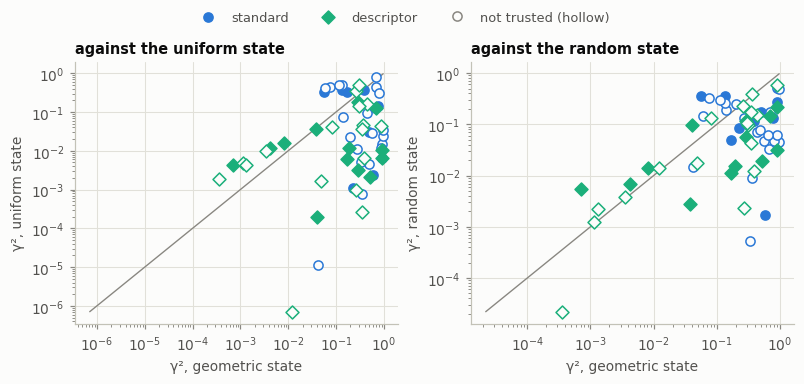

In [3]:
plotting.checks(
    [
        plotting.Check(
            {form: kinds[kind] for form, kinds in controls.items()},
            "geometric_gamma2",
            "gamma2",
            "γ², geometric state",
            f"γ², {kind} state",
            f"against the {kind} state",
        )
        for kind in KINDS
    ]
);

The degree when the gap is underestimated, against the degree at the gap itself: the time grows
with 1/Δ, so the filter pays for the margin.

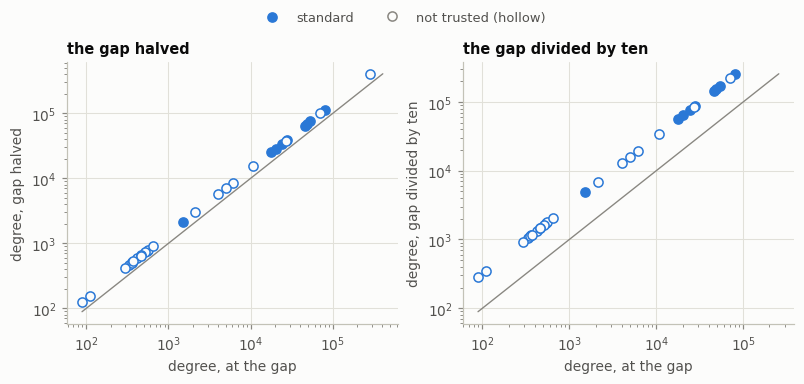

In [4]:
plotting.checks(
    [
        plotting.Check(
            {"standard": protocol},
            "gap_degree",
            f"{name}_degree",
            "degree, at the gap",
            f"degree, gap {factor}",
            f"the gap {factor}",
        )
        for name, factor in (("gap_half", "halved"), ("gap_tenth", "divided by ten"))
    ]
);

**What this does not show.** The controls run the minimax filter in both forms, and the
gap-underestimate runs the standard form's QITE only; the paper's own time rule is notebook 12's. The random control is one seeded state per case.